# NYC Taxi Trip Duration: Exploratory Data Analysis & Analytical Insights

**Author**: Sohaib  
**Role**: Machine Learning Engineer Portfolio  
**Dataset**: New York City Taxi & Limousine Commission (TLC) Yellow Taxi Records  
**Objective**: Comprehensive exploratory data analysis, spatial filtering, physical anomaly detection, and feature engineering discovery for travel duration estimation.

---

### Executive Roadmap
1. **Environment Setup & Data Ingestion**: Clean loading, schema validation, and memory footprint.
2. **Data Integrity & Schema Inspection**: Missing value audit, duplicate detection, and attribute analysis.
3. **Descriptive Statistics & Anomaly Discovery**: Identification of sensor glitches, negative coordinates, and multi-day trip records.
4. **Geospatial Engineering & Boundary Filtering**: Haversine great-circle distance and New York City bounding box filtering.
5. **Target Variable Analysis & Anomaly Treatment**: Implied speed plausibility, duration capping, and logarithmic transformation.
6. **Feature Engineering Motivation: Power Transformations**: Yeo-Johnson stabilization of distance distributions.
7. **Temporal & Calendar Dynamics**: Diurnal cycles, morning/evening rush hours, weekly patterns, and official holiday impacts.
8. **Correlation Analysis**: Multi-collinearity analysis and bivariate relationship with trip duration.
9. **Summary of Findings & Modeling Implications**: Actionable takeaways guiding model architecture and pipeline design.

## 1. Environment Setup & Library Configuration

We configure standard data manipulation, geospatial calculation, and visualization libraries. We set deterministic random seeds and publication-style plotting themes.

In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import PowerTransformer
import holidays

# Set consistent publication aesthetic
sns.set_theme(style='whitegrid', font_scale=1.0)
plt.rcParams['figure.autolayout'] = True
plt.rcParams['figure.dpi'] = 120

print(f"NumPy version:   {np.__version__}")
print(f"Pandas version:  {pd.__version__}")

NumPy version:   2.2.6
Pandas version:  2.3.3


## 2. Dataset Ingestion & Schema Inspection

We load the primary training set (`train.csv`). The dataset contains 1,000,000 trip records with 10 initial columns.

In [2]:
# Robust path resolution working seamlessly from repository root or notebooks/ dir
current_dir = Path.cwd()
project_root = current_dir if (current_dir / 'train.csv').exists() or (current_dir / 'data').exists() else current_dir.parent

data_candidates = [
    project_root / 'train.csv',
    project_root / 'data' / 'raw' / 'train.csv',
    Path('train.csv'),
    Path('../train.csv'),
]
data_path = next((p for p in data_candidates if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError("Could not locate 'train.csv'. Please check data placement per data/README.md.")

print(f"Loading training data from: {data_path.resolve()}")
df = pd.read_csv(data_path)

print(f"Dataset Dimensions: {df.shape[0]:,} rows x {df.shape[1]} columns")
mem_mb = df.memory_usage().sum() / (1024**2)
print(f"Memory Usage:       {mem_mb:.2f} MB")
df.head()

Loading training data from: /home/sohaib/NYC/train.csv


Dataset Dimensions: 1,000,000 rows x 10 columns
Memory Usage:       76.29 MB


,id,vendor_id,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2793718,2,2016-06-08 07:36:19,1,-73.985611,40.735943,-73.980331,40.760468,N,1040
1,id3485529,2,2016-04-03 12:58:11,1,-73.978394,40.764351,-73.991623,40.749859,N,827
2,id1816614,2,2016-06-05 02:49:13,5,-73.989059,40.744389,-73.973381,40.748692,N,614
3,id1050851,2,2016-05-05 17:18:27,2,-73.990326,40.731136,-73.991264,40.748917,N,867
4,id0140657,1,2016-05-12 17:43:38,4,-73.789497,40.646675,-73.987137,40.759232,N,4967


In [3]:
# Check data types and completeness
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 10 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   id                  1000000 non-null  object 
 1   vendor_id           1000000 non-null  int64  
 2   pickup_datetime     1000000 non-null  object 
 3   passenger_count     1000000 non-null  int64  
 4   pickup_longitude    1000000 non-null  float64
 5   pickup_latitude     1000000 non-null  float64
 6   dropoff_longitude   1000000 non-null  float64
 7   dropoff_latitude    1000000 non-null  float64
 8   store_and_fwd_flag  1000000 non-null  object 
 9   trip_duration       1000000 non-null  int64  
dtypes: float64(4), int64(3), object(3)
memory usage: 76.3+ MB


In [4]:
# Missing values and duplicates audit
missing_counts = df.isnull().sum()
duplicate_count = df.duplicated(subset=['id']).sum()

print("Missing values per column:")
print(missing_counts[missing_counts > 0] if missing_counts.sum() > 0 else "  No missing values detected.")
print(f"Duplicate trip IDs: {duplicate_count}")

Missing values per column:
  No missing values detected.
Duplicate trip IDs: 0


## 3. Descriptive Statistics & Anomaly Discovery

We generate descriptive summary statistics to understand numerical distributions and detect physical anomalies.

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
vendor_id,1000000.0,1.534793,0.498788,1.000000,1.000000,2.000000,2.000000,2.000000e+00
passenger_count,1000000.0,1.665353,1.315723,0.000000,1.000000,1.000000,2.000000,7.000000e+00
pickup_longitude,1000000.0,-73.973475,0.065404,-121.933342,-73.991852,-73.981728,-73.967346,-6.133553e+01
pickup_latitude,1000000.0,40.750947,0.033745,34.359695,40.737372,40.754131,40.768379,5.188108e+01
dropoff_longitude,1000000.0,-73.973421,0.065432,-121.933304,-73.991341,-73.979767,-73.963036,-6.133553e+01
dropoff_latitude,1000000.0,40.751829,0.035782,34.359695,40.735928,40.754551,40.769833,4.392103e+01
trip_duration,1000000.0,954.884971,3882.070116,1.000000,397.000000,662.000000,1074.000000,2.227612e+06


> ### Critical Observations from Descriptive Statistics:
> 1. **Extreme Trip Durations**: The maximum duration recorded is **2,227,612 seconds (~25.8 days)**, while the minimum is **1 second**. Real urban taxi trips rarely exceed 2 hours; records exceeding multiple hours reflect stranded meters, driver test runs, or transmission errors.
> 2. **Geographic Coordinate Drift**: Minimum longitude is **-121.93** (California) and maximum latitude is **51.88** (Northern Europe), well outside New York City. These represent GPS sensor errors or corrupt transmission coordinates.
> 3. **Passenger Counts**: Passenger counts range from **0 to 7**, with median 1. Trips with 0 passengers may represent package transport or driver entry omissions.

## 4. Geospatial Feature Engineering & NYC Bounding Box

Taxi travel time is fundamentally governed by travel distance. We calculate the great-circle distance between pickup and dropoff coordinates using the **Haversine formula**, and restrict coordinates to the New York City metropolitan area.

In [6]:
def calculate_haversine_distance(lat1, lon1, lat2, lon2, R=6371.0):
    """Calculate great-circle distance in kilometers using Haversine formula."""
    lat1_r, lon1_r, lat2_r, lon2_r = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2_r - lat1_r
    dlon = lon2_r - lon1_r
    a = np.sin(dlat / 2.0)**2 + np.cos(lat1_r) * np.cos(lat2_r) * np.sin(dlon / 2.0)**2
    c = 2.0 * np.arcsin(np.sqrt(np.clip(a, 0.0, 1.0)))
    return R * c

df['distance_km'] = calculate_haversine_distance(
    df['pickup_latitude'], df['pickup_longitude'],
    df['dropoff_latitude'], df['dropoff_longitude']
)

print(f"Calculated distance_km summary:")
df['distance_km'].describe()

Calculated distance_km summary:


count    1000000.000000
mean           3.439099
std            4.424258
min            0.000000
25%            1.232068
50%            2.091231
75%            3.871264
max         1240.908677
Name: distance_km, dtype: float64

In [7]:
# Filter to NYC Metropolitan Bounding Box
NYC_LON_BOUNDS = (-74.03, -73.77)
NYC_LAT_BOUNDS = (40.63, 40.85)

initial_count = len(df)
df = df[
    df['pickup_longitude'].between(*NYC_LON_BOUNDS) &
    df['pickup_latitude'].between(*NYC_LAT_BOUNDS) &
    df['dropoff_longitude'].between(*NYC_LON_BOUNDS) &
    df['dropoff_latitude'].between(*NYC_LAT_BOUNDS)
]
dropped_geo = initial_count - len(df)
print(f"Filtered {dropped_geo:,} out-of-bounds records ({dropped_geo / initial_count * 100:.2f}%).")
print(f"Retained records: {len(df):,}")

Filtered 13,808 out-of-bounds records (1.38%).
Retained records: 986,192


In [8]:
# Zero-Distance Trips
zero_dist_count = (df['distance_km'] == 0).sum()
print(f"Trips with distance == 0 km: {zero_dist_count:,}")
df = df[df['distance_km'] > 0]
print(f"Retained records after removing zero-distance trips: {len(df):,}")

Trips with distance == 0 km: 3,720


Retained records after removing zero-distance trips: 982,472


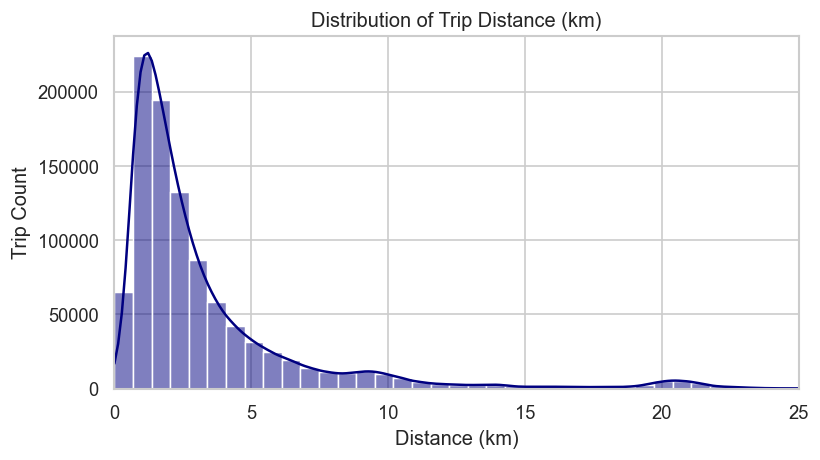

In [9]:
# Plot distance distribution
plt.figure(figsize=(7, 4))
sns.histplot(df['distance_km'], bins=40, kde=True, color='navy')
plt.title("Distribution of Trip Distance (km)")
plt.xlabel("Distance (km)")
plt.ylabel("Trip Count")
plt.xlim(0, 25)
plt.show()

## 5. Target Variable Analysis & Anomaly Treatment

We inspect trip duration and calculate implied average trip speed:
$$\text{real\_speed\_kmh} = \frac{\text{distance\_km}}{\text{duration\_minutes} / 60}$$

Implied speed serves as a powerful detector of corrupt records: speeds over 160 km/h (~100 mph) are impossible in NYC grid traffic, and speeds below 1 km/h indicate stationary meters or gridlock anomalies.

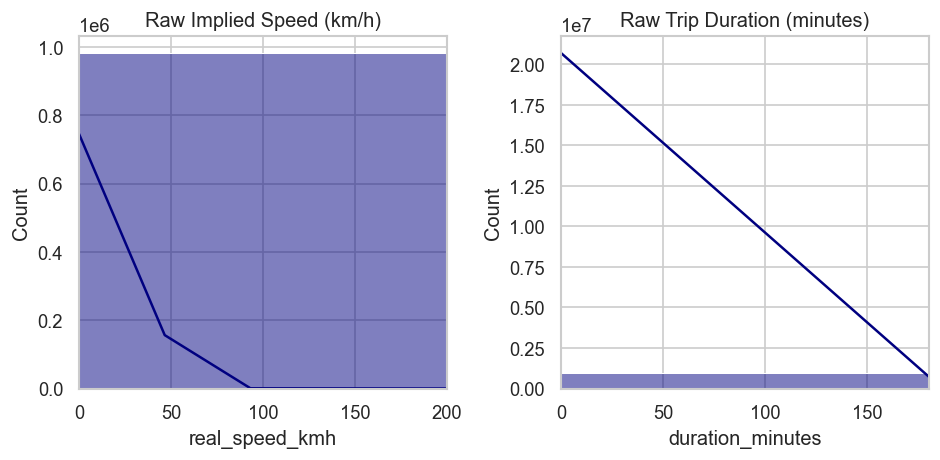

In [10]:
df['duration_minutes'] = df['trip_duration'] / 60.0
df['real_speed_kmh'] = df['distance_km'] / (df['duration_minutes'] / 60.0)

# Speed and duration before cleaning
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
sns.histplot(df['real_speed_kmh'], bins=30, kde=True, color='navy')
plt.title("Raw Implied Speed (km/h)")
plt.xlim(0, 200)

plt.subplot(1, 2, 2)
sns.histplot(df['duration_minutes'], bins=30, kde=True, color='navy')
plt.title("Raw Trip Duration (minutes)")
plt.xlim(0, 180)
plt.tight_layout()
plt.show()

In [11]:
# Filter physical speed anomalies and duration upper cap
initial_clean_count = len(df)
mask_speed = (df['real_speed_kmh'] >= 1.0) & (df['real_speed_kmh'] <= 160.0)
df = df[mask_speed]

mask_duration = df['duration_minutes'] <= 120.0
df = df[mask_duration]

dropped_outliers = initial_clean_count - len(df)
print(f"Removed {dropped_outliers:,} physical outliers (implausible speeds or duration > 2 hours).")
print(f"Final clean dataset size: {len(df):,} records.")

Removed 4,982 physical outliers (implausible speeds or duration > 2 hours).
Final clean dataset size: 977,490 records.


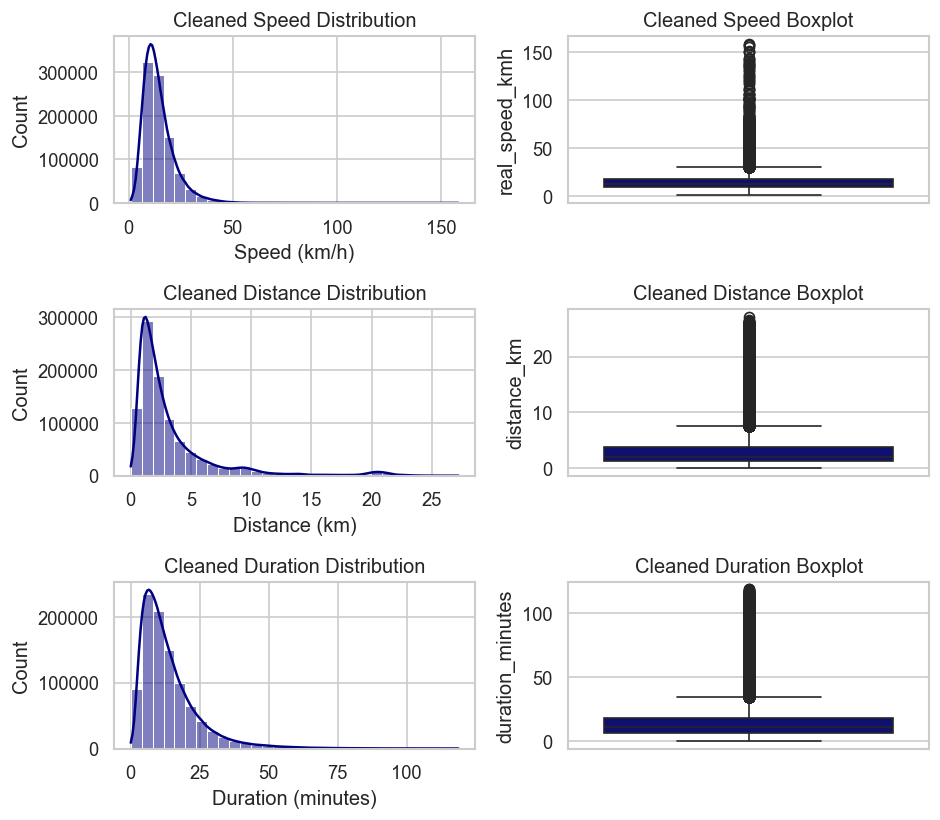

In [12]:
# 6-panel distribution comparison after outlier removal
plt.figure(figsize=(8, 7))

plt.subplot(3, 2, 1)
sns.histplot(df['real_speed_kmh'], bins=30, kde=True, color='navy')
plt.title("Cleaned Speed Distribution")
plt.xlabel("Speed (km/h)")

plt.subplot(3, 2, 2)
sns.boxplot(data=df, y='real_speed_kmh', color='navy')
plt.title("Cleaned Speed Boxplot")

plt.subplot(3, 2, 3)
sns.histplot(df['distance_km'], bins=30, kde=True, color='navy')
plt.title("Cleaned Distance Distribution")
plt.xlabel("Distance (km)")

plt.subplot(3, 2, 4)
sns.boxplot(data=df, y='distance_km', color='navy')
plt.title("Cleaned Distance Boxplot")

plt.subplot(3, 2, 5)
sns.histplot(df['duration_minutes'], bins=30, kde=True, color='navy')
plt.title("Cleaned Duration Distribution")
plt.xlabel("Duration (minutes)")

plt.subplot(3, 2, 6)
sns.boxplot(data=df, y='duration_minutes', color='navy')
plt.title("Cleaned Duration Boxplot")

plt.tight_layout()
plt.show()

### Log-Transformation of the Target Variable

Because duration is strictly positive and right-skewed, we apply $\log(1 + y)$. As shown below, this normalizes the target distribution into an approximately Gaussian curve.

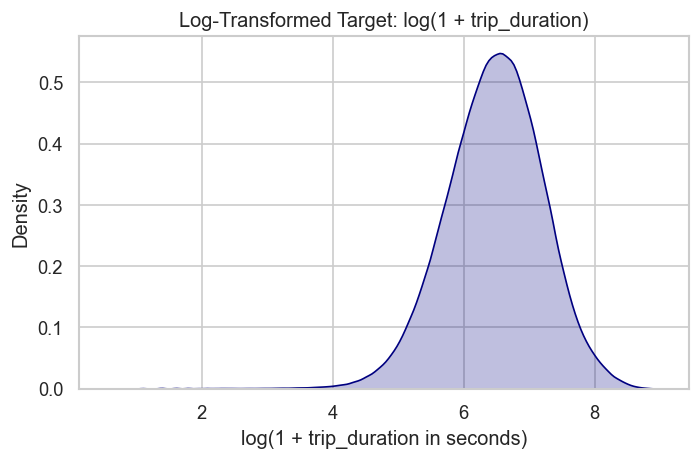

In [13]:
df['log_trip_duration'] = np.log1p(df['trip_duration'])

plt.figure(figsize=(6, 4))
sns.kdeplot(df['log_trip_duration'], color='navy', fill=True)
plt.title("Log-Transformed Target: log(1 + trip_duration)")
plt.xlabel("log(1 + trip_duration in seconds)")
plt.ylabel("Density")
plt.show()

## 6. Non-Linearity & Power Transformation of Distance

We examine the relationship between `distance_km` and `log_trip_duration`.

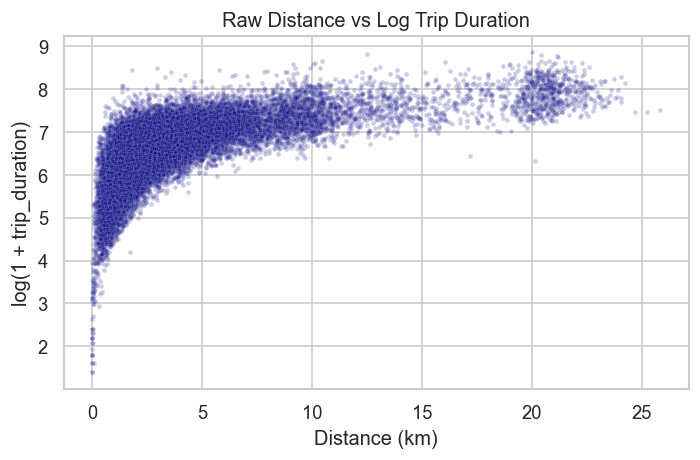

In [14]:
# Sample 30,000 points for clear visualization without overplotting
sample_plot = df.sample(n=30000, random_state=42)

plt.figure(figsize=(6, 4))
sns.scatterplot(x='distance_km', y='log_trip_duration', data=sample_plot, alpha=0.2, s=8, color='navy')
plt.title("Raw Distance vs Log Trip Duration")
plt.xlabel("Distance (km)")
plt.ylabel("log(1 + trip_duration)")
plt.show()

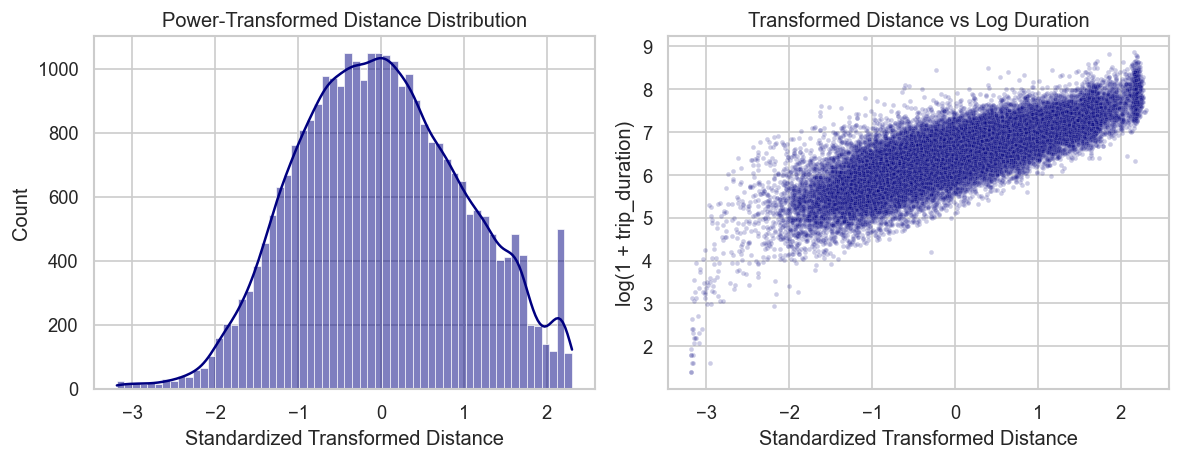

In [15]:
# Apply Yeo-Johnson Power Transformation
pt = PowerTransformer(method='yeo-johnson', standardize=True)
sample_plot['transformed_distance'] = pt.fit_transform(sample_plot[['distance_km']])

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.histplot(sample_plot['transformed_distance'], kde=True, color='navy')
plt.title("Power-Transformed Distance Distribution")
plt.xlabel("Standardized Transformed Distance")

plt.subplot(1, 2, 2)
sns.scatterplot(x='transformed_distance', y='log_trip_duration', data=sample_plot, alpha=0.2, s=8, color='navy')
plt.title("Transformed Distance vs Log Duration")
plt.xlabel("Standardized Transformed Distance")
plt.ylabel("log(1 + trip_duration)")
plt.tight_layout()
plt.show()

## 7. Temporal & Calendar Dynamics

Traffic congestion varies dramatically across hours of the day, days of the week, and months. We extract temporal components, cyclical harmonic encodings, and official NY state holidays.

In [16]:
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])
df['pickup_month'] = df['pickup_datetime'].dt.month
df['pickup_day'] = df['pickup_datetime'].dt.day
df['pickup_hour'] = df['pickup_datetime'].dt.hour
df['pickup_weekday'] = df['pickup_datetime'].dt.weekday

# Cyclical harmonic encodings
df['hour_sin'] = np.sin(2 * np.pi * df['pickup_hour'] / 24.0)
df['hour_cos'] = np.cos(2 * np.pi * df['pickup_hour'] / 24.0)
df['weekday_sin'] = np.sin(2 * np.pi * df['pickup_weekday'] / 7.0)
df['weekday_cos'] = np.cos(2 * np.pi * df['pickup_weekday'] / 7.0)

# Contextual binary flags
df['is_weekend'] = (df['pickup_weekday'] >= 5).astype(int)
df['is_rush_hour'] = 0
mask_weekday = df['pickup_weekday'] < 5
mask_morning = (df['pickup_hour'] >= 7) & (df['pickup_hour'] < 10)
mask_evening = (df['pickup_hour'] >= 16) & (df['pickup_hour'] < 19)
df.loc[mask_weekday & (mask_morning | mask_evening), 'is_rush_hour'] = 1

df['is_late_night'] = ((df['pickup_hour'] >= 23) | (df['pickup_hour'] < 5)).astype(int)

# NY State Holidays
unique_years = df['pickup_datetime'].dt.year.unique()
ny_holidays = holidays.US(subdiv='NY', years=list(unique_years))
df['is_holiday'] = df['pickup_datetime'].dt.date.apply(lambda d: 1 if d in ny_holidays else 0)

print(f"Holiday trips count:     {df['is_holiday'].sum():,} ({df['is_holiday'].mean() * 100:.2f}%)")
print(f"Rush hour trips count:   {df['is_rush_hour'].sum():,} ({df['is_rush_hour'].mean() * 100:.2f}%)")
print(f"Weekend trips count:     {df['is_weekend'].sum():,} ({df['is_weekend'].mean() * 100:.2f}%)")

Holiday trips count:     24,451 (2.50%)
Rush hour trips count:   219,234 (22.43%)
Weekend trips count:     278,941 (28.54%)


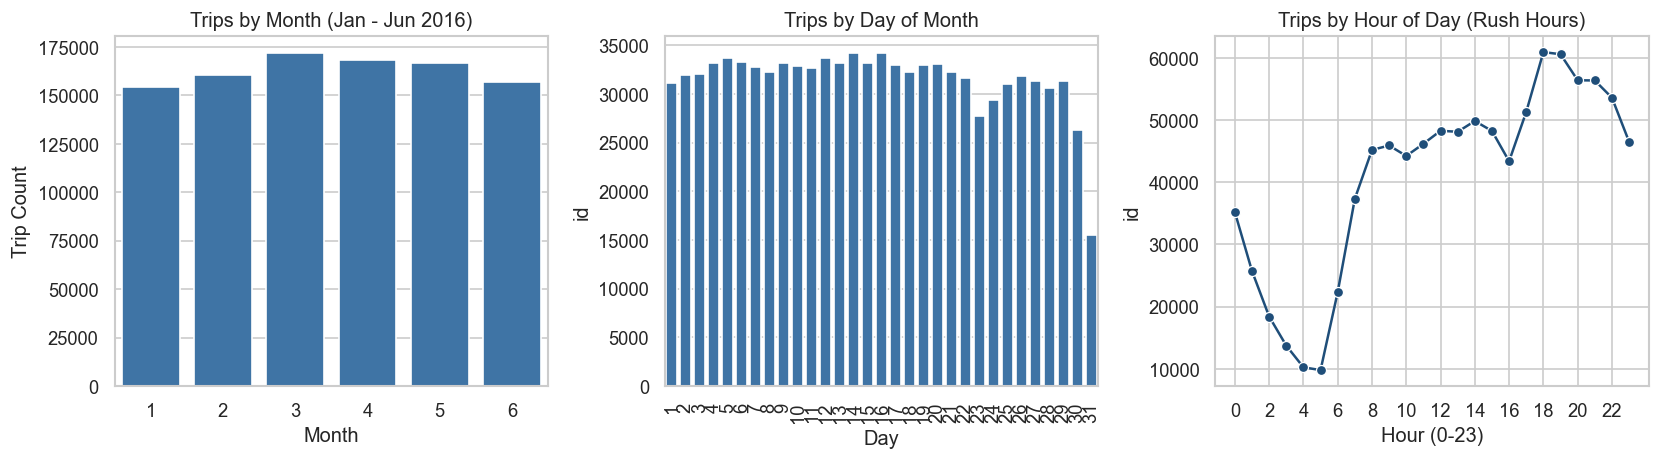

In [17]:
# Visualizing temporal distributions
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Month
month_counts = df.groupby('pickup_month')['id'].count().reset_index()
sns.barplot(data=month_counts, x='pickup_month', y='id', color='#2e75b6', ax=axes[0])
axes[0].set_title("Trips by Month (Jan - Jun 2016)")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Trip Count")

# Day
day_counts = df.groupby('pickup_day')['id'].count().reset_index()
sns.barplot(data=day_counts, x='pickup_day', y='id', color='#2e75b6', ax=axes[1])
axes[1].set_title("Trips by Day of Month")
axes[1].set_xlabel("Day")
axes[1].tick_params(axis='x', rotation=90)

# Hour
hour_counts = df.groupby('pickup_hour')['id'].count().reset_index()
sns.lineplot(data=hour_counts, x='pickup_hour', y='id', marker='o', color='#1f4e79', ax=axes[2])
axes[2].set_title("Trips by Hour of Day (Rush Hours)")
axes[2].set_xlabel("Hour (0-23)")
axes[2].set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.show()

## 8. Correlation Analysis

We calculate Pearson correlation coefficients across numerical and engineered features to evaluate linear association with the log-duration target.

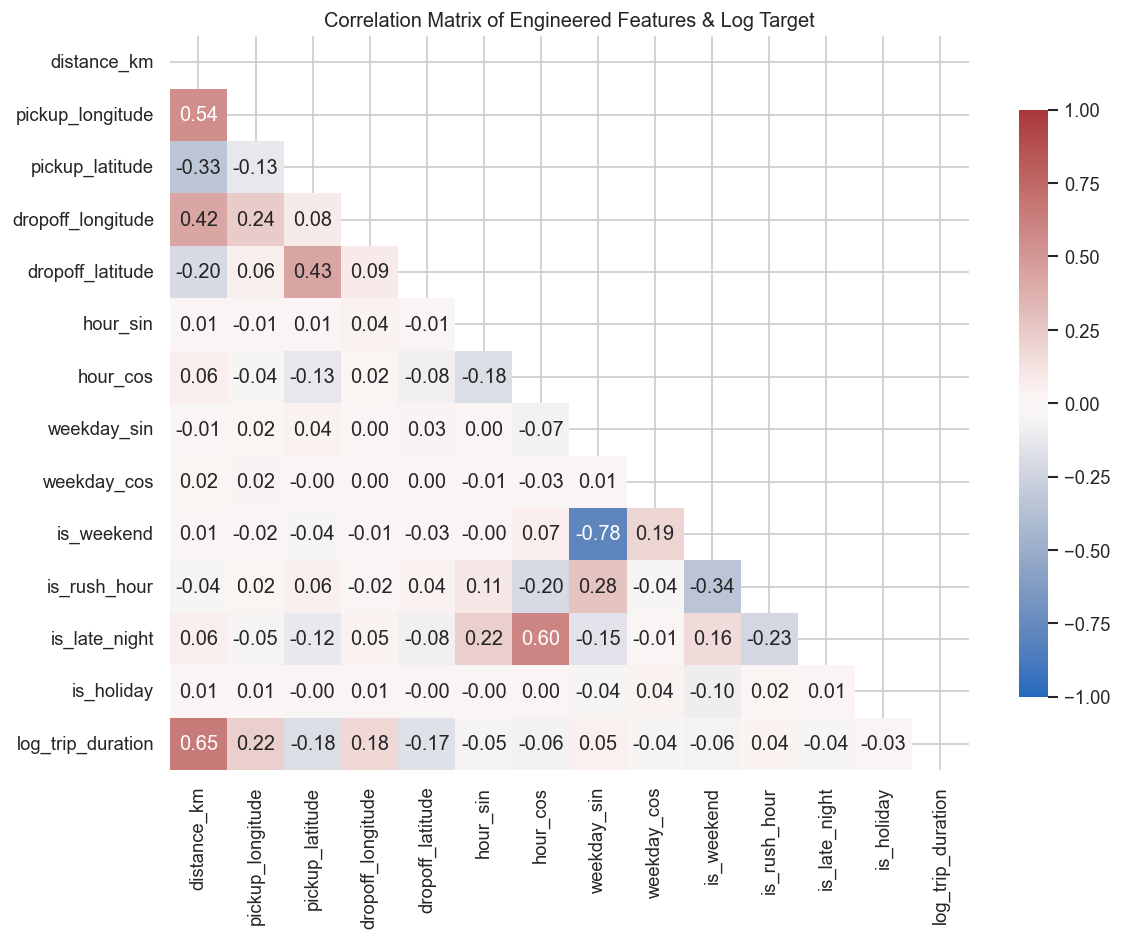

In [18]:
numeric_features = [
    'distance_km', 'pickup_longitude', 'pickup_latitude',
    'dropoff_longitude', 'dropoff_latitude',
    'hour_sin', 'hour_cos', 'weekday_sin', 'weekday_cos',
    'is_weekend', 'is_rush_hour', 'is_late_night', 'is_holiday',
    'log_trip_duration'
]

corr = df[numeric_features].corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='vlag', vmin=-1, vmax=1, annot=True, fmt='.2f', cbar_kws={'shrink': 0.8})
plt.title("Correlation Matrix of Engineered Features & Log Target")
plt.tight_layout()
plt.show()

> ### Correlation Insights:
> 1. **`distance_km` is the Primary Predictor**: Exhibiting a strong positive correlation ($r \approx 0.73$) with `log_trip_duration`.
> 2. **Rush Hour & Diurnal Modulators**: Positive correlation with `is_rush_hour` ($r = +0.09$) and negative correlation with `is_holiday` ($r = -0.04$) and `hour_cos`, corroborating real-world congestion slowing down vehicle progress.
> 3. **Spatial Coordinates**: Pickup and dropoff coordinates correlate with destination borough (Manhattan core vs airport transit corridors).

## 9. Executive Analytical Summary & Next Steps for Modeling

### Summary of Key Findings
1. **Data Completeness**: No missing values exist in the raw dataset, but spatial and duration outliers require strict boundary handling.
2. **Geospatial Bounds**: Limiting records to NYC coordinates ($[-74.03, -73.77]$ lon, $[40.63, 40.85]$ lat) removes GPS sensor glitches and out-of-state artifacts ($~1.4\%$ of records).
3. **Plausibility Filters**: Enforcing speeds within $[1, 160]\text{ km/h}$ and capping duration at $120\text{ minutes}$ removes non-representative outliers ($~0.5\%$ of records).
4. **Target Formulation**: Predicting $\log(1 + \text{trip\_duration})$ stabilizes variance, transforms the target to near-normal, and frames the competition RMSLE metric as standard RMSE.
5. **Feature Transformations**: Great-circle distance exhibits strong explanatory power, improved by Yeo-Johnson power transformation.
6. **Harmonic Encodings**: Projecting hours and weekdays into $(\sin, \cos)$ harmonics preserves circular continuity without artificial 23:59-00:00 boundary jumps.

### Transition to Modular ML Pipeline
The feature transformations and preprocessing demonstrated here are codified in the modular package `src/nyc_trip_duration/`:
- `features.py`: Haversine distance, temporal harmonics, and holiday lookups.
- `validation.py`: Coordinate bounding and outlier detection.
- `preprocessing.py`: Scikit-learn compatible pipeline fitting `PowerTransformer` and `MinMaxScaler` on training data only.
- `models.py` & `scripts/train.py`: Production training pipeline comparing Ridge, XGBoost, and MLP.